# Evaluación del modelo

**Lo que queremos hacer.** Medir el LGBM ajustado sobre 2026 con **matriz de confusión**, accuracy, precisión,
recall y F1, y comprobar que el resultado es estable en el tiempo.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "lib"))
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score)
from config import PROCESADOS, TAB, aplicar_estilo
import graficos as g

aplicar_estilo()
cfg = json.loads((RAIZ / "models" / "lgbm_final.json").read_text(encoding="utf-8"))
modelo = lgb.Booster(model_file=str(RAIZ / "models" / "lgbm_final.txt"))
test = pd.read_parquet(PROCESADOS / "modelado_test.parquet")
X_test, y_test = test.drop(columns=["arr_del15", "fecha"]), test.arr_del15
probs = modelo.predict(X_test)
print(f"test {X_test.shape} | umbral guardado {cfg['umbral']:.2f} | AUC {roc_auc_score(y_test, probs):.3f}")

test (4608866, 35) | umbral guardado 0.28 | AUC 0.782


## 1. Métricas en 2026

Se comparan los dos umbrales: el 0,50 por defecto y el elegido en validación (0,28). La **accuracy**
se incluye para mostrar por qué no basta: con un 23,6 % de retrasos, acertar siempre «puntual» da
76,4 % sin detectar nada.

In [2]:
def medir(umbral):
    pred = (probs >= umbral).astype(int)
    return {"umbral": round(umbral, 2), "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred), "auc": roc_auc_score(y_test, probs)}

metricas = pd.DataFrame([medir(.5), medir(cfg["umbral"])]).set_index("umbral")
metricas.round(3)

,accuracy,precision,recall,f1,auc
umbral,,,,,
0.50,0.824,0.744,0.385,0.508,0.782
0.28,0.787,0.547,0.559,0.553,0.782


## 2. Matriz de confusión

Cada celda cuenta vuelos: verdaderos negativos (puntual y dicho puntual), falsos positivos (aviso
innecesario), falsos negativos (retraso no avisado) y verdaderos positivos.

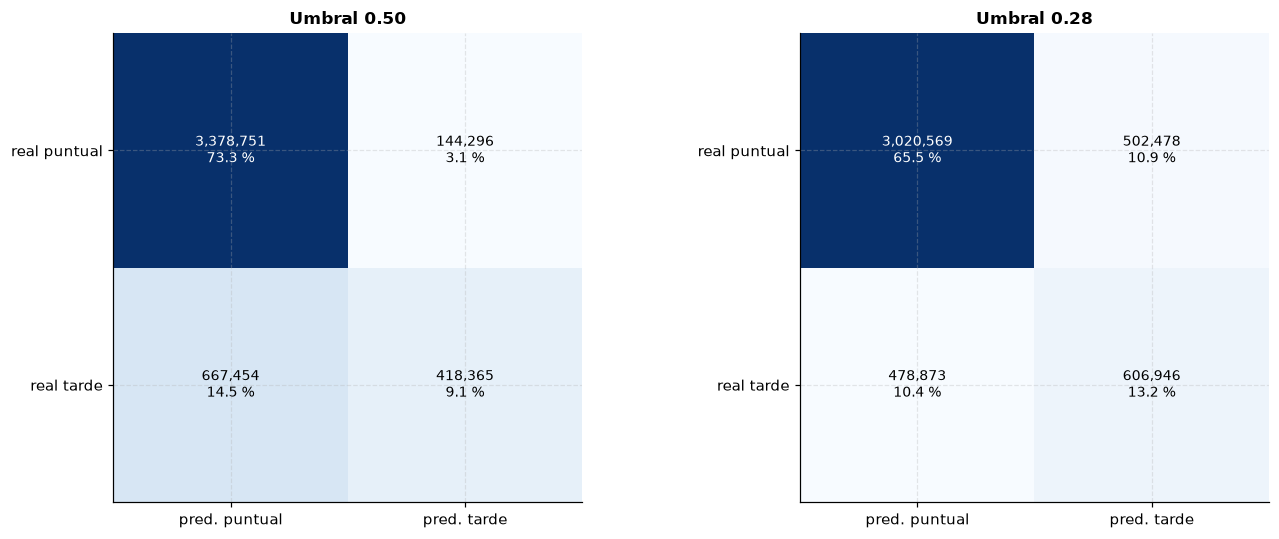

              precision    recall  f1-score   support

     puntual      0.863     0.857     0.860   3523047
       tarde      0.547     0.559     0.553   1085819

    accuracy                          0.787   4608866
   macro avg      0.705     0.708     0.707   4608866
weighted avg      0.789     0.787     0.788   4608866



In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for eje, umbral in zip(ax, [.5, cfg["umbral"]]):
    mc = confusion_matrix(y_test, (probs >= umbral).astype(int))
    eje.imshow(mc, cmap="Blues")
    eje.set_xticks([0, 1], ["pred. puntual", "pred. tarde"])
    eje.set_yticks([0, 1], ["real puntual", "real tarde"])
    eje.set_title(f"Umbral {umbral:.2f}")
    for i in range(2):
        for j in range(2):
            pct = mc[i, j] / mc.sum() * 100
            eje.text(j, i, f"{mc[i, j]:,}\n{pct:.1f} %", ha="center", va="center",
                     color="white" if mc[i, j] > mc.max() / 2 else "black", fontsize=9)
g.guardar(fig, "17_matrices_confusion.png")
plt.show()
print(classification_report(y_test, (probs >= cfg["umbral"]).astype(int),
                            target_names=["puntual", "tarde"], digits=3))

## 3. Curvas y estabilidad

La curva ROC mide la capacidad de ordenar; la de precisión-recall es más informativa con clases
desbalanceadas. El F1 por mes comprueba que el rendimiento no depende de una estación concreta.

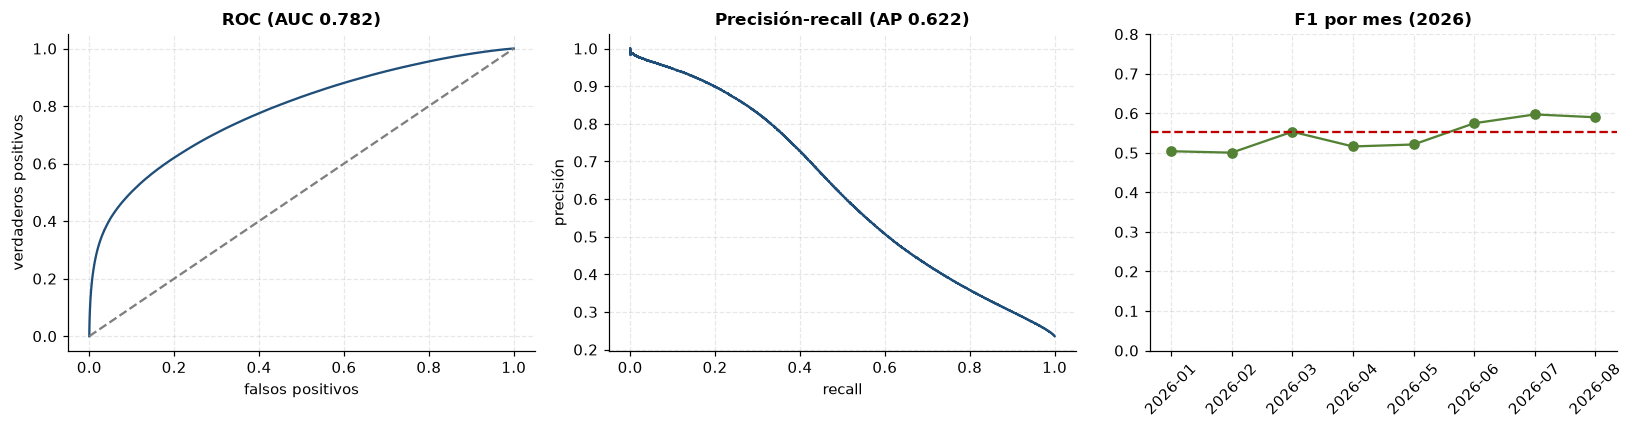

,F1
2026-01,0.504
2026-02,0.500
2026-03,0.553
2026-04,0.516
2026-05,0.521
2026-06,0.575
2026-07,0.597
2026-08,0.590


In [4]:
fpr, tpr, _ = roc_curve(y_test, probs)
prec, rec, _ = precision_recall_curve(y_test, probs)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(fpr, tpr, color="#1f4e79")
ax[0].plot([0, 1], [0, 1], "--", color="#7f7f7f")
ax[0].set_title(f"ROC (AUC {roc_auc_score(y_test, probs):.3f})")
ax[0].set_xlabel("falsos positivos"); ax[0].set_ylabel("verdaderos positivos")

ax[1].plot(rec, prec, color="#1f4e79")
ax[1].set_title(f"Precisión-recall (AP {average_precision_score(y_test, probs):.3f})")
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precisión")

mes = test.fecha.dt.to_period("M").astype(str)
f1_mes = pd.Series({m: f1_score(y_test[mes == m], (probs[mes == m] >= cfg["umbral"]).astype(int))
                    for m in sorted(mes.unique())})
ax[2].plot(f1_mes.index, f1_mes.values, "o-", color="#548235")
ax[2].axhline(metricas["f1"].iloc[-1], ls="--", color="#c00000")
ax[2].set_title("F1 por mes (2026)"); ax[2].set_ylim(0, .8); ax[2].tick_params(axis="x", rotation=45)
g.guardar(fig, "18_curvas.png")
plt.show()
f1_mes.round(3).to_frame("F1")

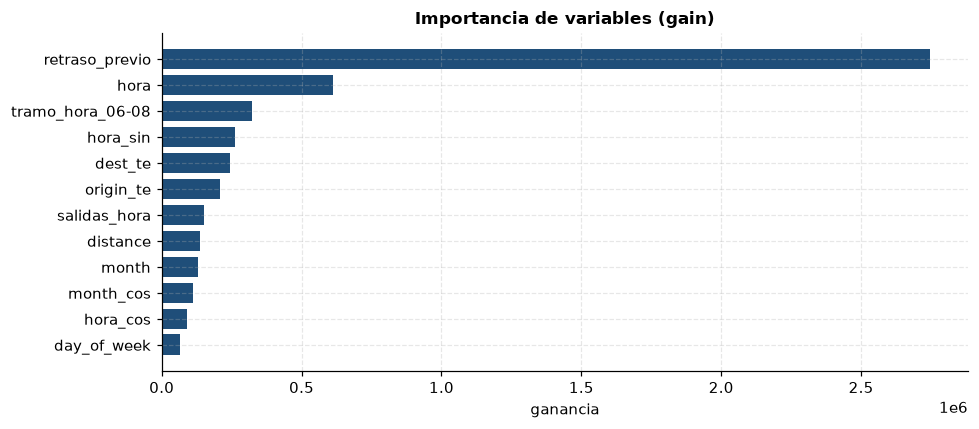

,gain
retraso_previo,2744775.0
hora,613496.0
tramo_hora_06-08,322369.0
hora_sin,261498.0
dest_te,244833.0
origin_te,207288.0
salidas_hora,151852.0
distance,137970.0
month,131526.0
month_cos,112296.0


In [5]:
imp = pd.Series(modelo.feature_importance(importance_type="gain"),
                index=X_test.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(imp.head(12)[::-1].index, imp.head(12)[::-1].values, color="#1f4e79")
ax.set_title("Importancia de variables (gain)")
ax.set_xlabel("ganancia")
g.guardar(fig, "19_importancia.png")
plt.show()
imp.head(12).round(0).to_frame("gain")

## 4. Lectura de los resultados

| Métrica | Umbral 0,50 | Umbral óptimo | Qué significa |
|---|---|---|---|
| Accuracy | 0,824 | 0,787 | Acierta 4 de cada 5; baja al avisar más |
| Precisión | 0,744 | 0,547 | De cada 100 avisos, 55 son retrasos reales |
| Recall | 0,385 | 0,559 | Detecta 56 de cada 100 retrasos |
| F1 | 0,508 | **0,553** | Equilibrio entre avisar de más y de menos |
| AUC | 0,782 | 0,782 | Buena capacidad de ordenar; el umbral no la cambia |

El umbral bajo mejora recall y F1 casi sin coste en accuracy: se cambia «acertar más» por «detectar
más», que es lo que necesita un aviso operativo.

In [6]:
metricas.round(4).to_csv(TAB / "07_evaluacion_modelo.csv", sep=";", decimal=",", encoding="utf-8-sig")
pd.DataFrame(confusion_matrix(y_test, (probs >= cfg["umbral"]).astype(int)),
             index=["real puntual", "real tarde"],
             columns=["pred puntual", "pred tarde"]).to_csv(
    TAB / "08_confusion_test.csv", sep=";", decimal=",", encoding="utf-8-sig")
f1_mes.round(4).to_frame("F1").to_csv(TAB / "09_f1_mensual.csv", sep=";", decimal=",", encoding="utf-8-sig")
imp.head(15).round(1).to_frame("gain").to_csv(TAB / "06_importancia_variables.csv", sep=";", decimal=",", encoding="utf-8-sig")
print("tablas exportadas:", ", ".join(p.name for p in sorted(TAB.glob("0[789]*.csv"))))

tablas exportadas: 07_evaluacion_modelo.csv, 08_confusion_test.csv, 09_f1_mensual.csv


## Dudas y cosas que no nos salieron

- Al principio nos fijamos en la accuracy (0,787) y pensamos que el modelo era buenísimo. Después
  vimos que acertar «puntual» siempre ya da 0,764, así que la accuracy sola no dice nada.
- No sabemos si el umbral 0,28 sirve para cualquier año; en 2026 funciona, pero habría que revisarlo
  si cambian las condiciones.
- Nos quedamos con ganas de probar un modelo por aerolínea, pero se nos acabó el tiempo.